# Exploratory market analysis

This notebook audits market missingness and temporal gaps, estimates the documented HAC extensions, and demonstrates a full-rank tourism specification. These estimates are independent extensions because the original A-D design matrices are unavailable.

In [1]:
from pathlib import Path
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent.resolve()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from broadway_research.ingest import load

# Public clones must supply the authorized six-sheet workbook separately.
# Set BROADWAY_INPUT_DIR to the directory containing that workbook.
input_value = os.environ.get("BROADWAY_INPUT_DIR")
if not input_value:
    raise FileNotFoundError("Set BROADWAY_INPUT_DIR to the authorized workbook directory.")
input_dir = Path(input_value)
if not input_dir.exists() or not list(input_dir.glob("*.xlsx")):
    raise FileNotFoundError(
        "Authorized source workbook not found. Set BROADWAY_INPUT_DIR to its containing directory. "
        "The workbook is intentionally excluded from the public repository."
    )

production, market = load(input_dir)
print(f"Loaded authorized inputs: {production.shape[0]} production aggregates and {market.shape[0]} market weeks")

Loaded authorized inputs: 67 production aggregates and 501 market weeks


In [2]:
market = market.sort_values("week_ending").reset_index(drop=True)
missing_by_year = market.assign(
    unemployment_missing=market["unemployment_rate_pct"].isna()
).groupby("year")["unemployment_missing"].agg(["sum", "count"])
missing_by_year["rate"] = missing_by_year["sum"] / missing_by_year["count"]
assert int(missing_by_year["sum"].sum()) == 244
missing_by_year

,sum,count,rate
year,,,
2015,31,31,1.000000
2016,52,52,1.000000
2017,53,53,1.000000
2018,52,52,1.000000
2019,52,52,1.000000
2020,0,10,0.000000
2021,0,21,0.000000
2022,0,52,0.000000
2023,0,53,0.000000


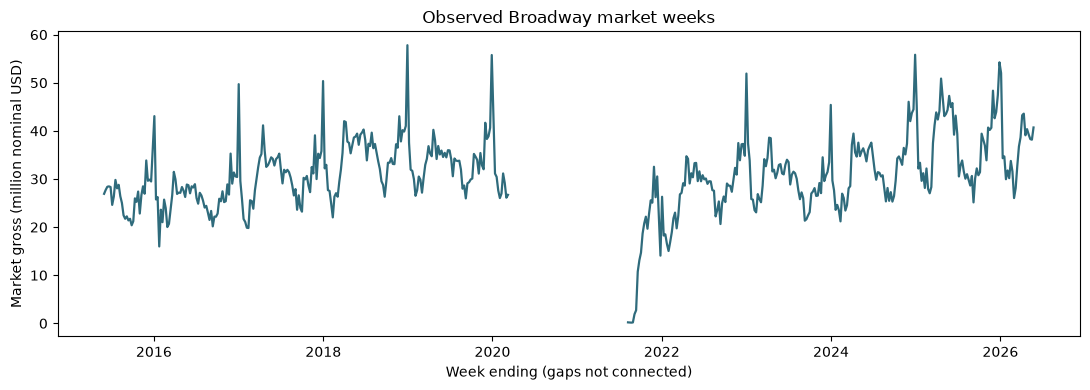

In [3]:
gaps = market["week_ending"].diff().dt.days
segments = gaps.gt(14).cumsum()
fig, ax = plt.subplots(figsize=(11, 4))
for _, segment in market.groupby(segments):
    ax.plot(segment["week_ending"], segment["market_gross_usd"] / 1e6, color="#2f6b7c", linewidth=1.6)
ax.set(xlabel="Week ending (gaps not connected)", ylabel="Market gross (million nominal USD)", title="Observed Broadway market weeks")
fig.tight_layout();

In [4]:
from broadway_research.market_analysis import models
from broadway_research.diagnostics import inspect

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    exploratory = models(market)
model_summary = []
for label, (specification, fitted) in exploratory.items():
    geometry = inspect(fitted)
    model_summary.append({
        "model": label, "N": int(fitted.nobs), "R_squared": fitted.rsquared,
        "rank": geometry["rank"], "columns": geometry["columns"],
        "condition_number": geometry["condition_number"], "formula": specification,
    })
pd.DataFrame(model_summary)

,model,N,R_squared,rank,columns,condition_number,formula
0,A,501,0.506952,24,24,17.118771,log_market_gross ~ holiday_week + C(month) + C...
1,B,257,0.698749,21,21,2915.288220,log_market_gross ~ holiday_week + C(month) + C...
2,C,236,0.707511,18,18,2198.631244,log_market_gross ~ holiday_week + C(month) + t...
3,D,257,0.696198,21,21,4392.805656,log_market_gross ~ holiday_week + C(month) + C...


In [5]:
import statsmodels.formula.api as smf

# Annual tourism and a full set of year dummies are structurally redundant.
# This alternative uses a continuous trend plus a reopening indicator, retaining
# month controls and the documented macro variables on complete cases.
market_extension = market.assign(
    time_years=(market["week_ending"] - market["week_ending"].min()).dt.days / 365.25,
    post_reopening=(market["week_ending"] >= pd.Timestamp("2021-09-14")).astype(int),
)
repaired_formula = (
    "log_market_gross ~ holiday_week + C(month) + "
    "time_years + post_reopening + unemployment_rate_pct + "
    "consumer_sentiment_monthly + nyc_visitors_millions_annual"
)
repaired = smf.ols(repaired_formula, market_extension).fit(cov_type="HAC", cov_kwds={"maxlags": 8})
geometry = inspect(repaired)
assert geometry["rank"] == geometry["columns"]
pd.Series({
    "status": "independent exploratory extension; not an exact paper reproduction",
    "N": int(repaired.nobs), "R_squared": repaired.rsquared,
    "adjusted_R_squared": repaired.rsquared_adj,
    "rank": geometry["rank"], "columns": geometry["columns"],
    "condition_number": geometry["condition_number"],
})

status                independent exploratory extension; not an exac...
N                                                                   236
R_squared                                                      0.707511
adjusted_R_squared                                             0.684702
rank                                                                 18
columns                                                              18
condition_number                                            2198.631244
dtype: object

In [6]:
terms = ["unemployment_rate_pct", "consumer_sentiment_monthly", "nyc_visitors_millions_annual", "holiday_week"]
intervals = repaired.conf_int()
pd.DataFrame({
    "estimate": repaired.params[terms],
    "HAC_standard_error": repaired.bse[terms],
    "HAC_p_value": repaired.pvalues[terms],
    "ci95_low": intervals.loc[terms, 0],
    "ci95_high": intervals.loc[terms, 1],
})

,estimate,HAC_standard_error,HAC_p_value,ci95_low,ci95_high
unemployment_rate_pct,-1.631931,0.407496,0.000062,-2.430608,-0.833254
consumer_sentiment_monthly,0.008675,0.007495,0.247097,-0.006015,0.023366
nyc_visitors_millions_annual,-0.061544,0.023116,0.007760,-0.106851,-0.016237
holiday_week,0.033524,0.030566,0.272742,-0.026385,0.093433


HAC inference allows residual heteroskedasticity and serial correlation through eight observed lags. It does not make repeated monthly or annual covariates equivalent to independent weekly measurements, and lag spacing across calendar gaps remains imperfect. The reopening indicator is a coarse structural-break control, not a causal pandemic adjustment.